In [3]:
import os
import csv
import random
import matplotlib
import matplotlib.pyplot as plt
from typing import Callable, Generic, TypeVar, cast
import numpy as np
import PIL.Image
import shutil
from PIL import Image
import time

import timm
import torch.nn as nn
import torch.optim as optim
import torch.onnx
import onnxruntime as ort

import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, matthews_corrcoef

import torch
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.optim.lr_scheduler import StepLR
import torchvision.models
import torchvision.transforms as T
from torchvision.datasets import ImageFolder
from accelerate import Accelerator

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

import warnings
warnings.filterwarnings('ignore')



Semua pustaka berhasil diimpor.


In [4]:
# ============================================
# 📦 STEP 1: INSTALL LIBRARIES
# ============================================
!pip install -q kaggle split-folders

import os
import splitfolders
from google.colab import files

# ============================================
# 🔑 STEP 2: KAGGLE API SETUP
# ============================================
print("📁 Upload your kaggle.json file (from Kaggle Account > API > Create New Token)")
files.upload()  # 👉 Upload kaggle.json

!mkdir -p ~/.kaggle
!mv kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# ============================================
# 📥 STEP 3: DOWNLOAD & UNZIP DATASET
# ============================================
!kaggle datasets download -d makiw4/alzheimer-types-impairment-and-dementia
!unzip -q alzheimer-types-impairment-and-dementia.zip -d alzheimer_data

# ============================================
# 🧩 STEP 4: FIND ACTUAL IMAGE FOLDER
# ============================================
base_path = "alzheimer_data"
subdirs = []
for root, dirs, files in os.walk(base_path):
    if any(f.lower().endswith(('.jpg', '.jpeg', '.png')) for f in files):
        subdirs.append(root)

# Find the parent folder that directly contains class folders
if len(subdirs) > 0:
    dataset_path = os.path.dirname(subdirs[0])
else:
    dataset_path = base_path

print("✅ Detected dataset folder:", dataset_path)
!ls "$dataset_path"

# ============================================
# 🧠 STEP 5: SPLIT INTO TRAIN / VAL / TEST
# ============================================
output_folder = "alzheimer_split"

splitfolders.ratio(dataset_path,
                   output=output_folder,
                   seed=42,
                   ratio=(.8, .1, .1),
                   move=False)

# ============================================
# ✅ STEP 6: VERIFY RESULT
# ============================================
!tree alzheimer_split -L 2


📁 Upload your kaggle.json file (from Kaggle Account > API > Create New Token)


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/makiw4/alzheimer-types-impairment-and-dementia
License(s): unknown
 96% 1.25G/1.30G [00:08<00:00, 202MB/s]
100% 1.30G/1.30G [00:08<00:00, 169MB/s]
✅ Detected dataset folder: alzheimer_data/alzheimer/Data
'Mild Dementia'      'Moderate Impairment'  'Very mild Dementia'
'Mild Impairment'    'No Impairment'	    'Very Mild Impairment'
'Moderate Dementia'  'Non Demented'


Copying files: 97956 files [00:17, 5524.19 files/s]


/bin/bash: line 1: tree: command not found


Train: 78362 images found.
Val: 9792 images found.
Test: 9802 images found.

✅ Classes: ['Mild Dementia', 'Mild Impairment', 'Moderate Dementia', 'Moderate Impairment', 'No Impairment', 'Non Demented', 'Very Mild Impairment', 'Very mild Dementia'] (8 total)

🚀 Using device: cuda


model.safetensors:   0%|          | 0.00/21.4M [00:00<?, ?B/s]

Epoch 1/10 - Training: 100%|██████████| 2449/2449 [06:07<00:00,  6.67it/s]



Epoch 1/10 | Train Loss: 0.2977 | Val Loss: 0.0806 | Train Acc: 88.60% | Val Acc: 96.71%
💾 Best model saved (Val Acc: 96.71%)


Epoch 2/10 - Training: 100%|██████████| 2449/2449 [05:31<00:00,  7.39it/s]


...


Epoch 7/10 | Train Loss: 0.0147 | Val Loss: 0.0092 | Train Acc: 99.51% | Val Acc: 99.68%


Epoch 8/10 - Training: 100%|██████████| 2449/2449 [05:30<00:00,  7.41it/s]



Epoch 8/10 | Train Loss: 0.0136 | Val Loss: 0.0127 | Train Acc: 99.52% | Val Acc: 99.50%


Epoch 9/10 - Training: 100%|██████████| 2449/2449 [05:32<00:00,  7.37it/s]



Epoch 9/10 | Train Loss: 0.0105 | Val Loss: 0.0166 | Train Acc: 99.65% | Val Acc: 99.41%
⏹️ Early stopping: no improvement for 3 epochs.


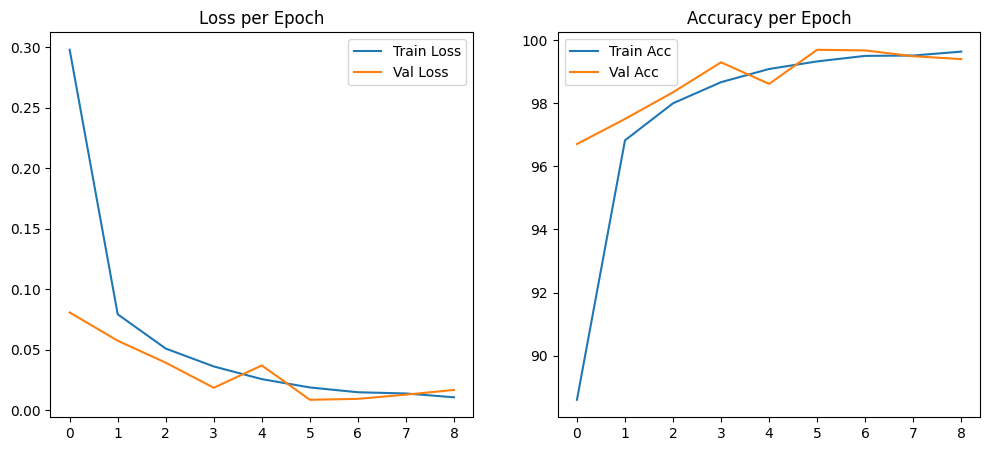

Testing: 100%|██████████| 307/307 [00:29<00:00, 10.32it/s]


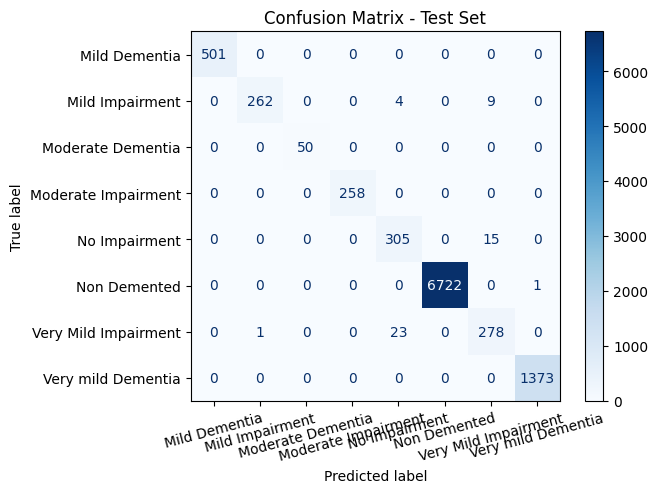


📋 Classification Report:
                      precision    recall  f1-score   support

       Mild Dementia       1.00      1.00      1.00       501
     Mild Impairment       1.00      0.95      0.97       275
   Moderate Dementia       1.00      1.00      1.00        50
 Moderate Impairment       1.00      1.00      1.00       258
       No Impairment       0.92      0.95      0.94       320
        Non Demented       1.00      1.00      1.00      6723
Very Mild Impairment       0.92      0.92      0.92       302
  Very mild Dementia       1.00      1.00      1.00      1373

            accuracy                           0.99      9802
           macro avg       0.98      0.98      0.98      9802
        weighted avg       0.99      0.99      0.99      9802



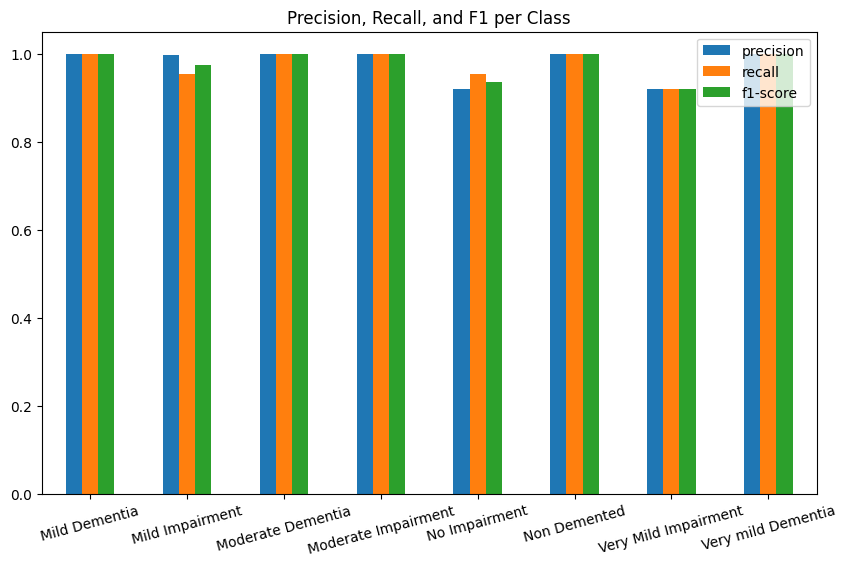

In [5]:
# ================================================================
# 🚀 EFFICIENTNET-B0 — Full Train + Validation + Test (GPU)
# ================================================================
!pip install -q timm seaborn tqdm scikit-learn matplotlib

import os, torch, time, timm
from torch import nn, optim
from torch.utils.data import DataLoader
from torchvision.datasets import ImageFolder
from torchvision import transforms
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from tqdm import tqdm
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# ================================================================
# 📁 DEFINE DATA PATHS (change if needed)
# ================================================================
base_dir = "/content/alzheimer_split"  # 🔹 Change if your dataset folder is elsewhere
train_dir = os.path.join(base_dir, "train")
val_dir   = os.path.join(base_dir, "val")
test_dir  = os.path.join(base_dir, "test")

# Validate folder existence
for d in [train_dir, val_dir, test_dir]:
    if not os.path.exists(d):
        raise FileNotFoundError(f"❌ Folder not found: {d}\nPlease upload or mount your dataset correctly.")

# ================================================================
# 🔍 Check if images exist
# ================================================================
def count_images(root):
    exts = (".jpg", ".jpeg", ".png")
    total = sum(len([f for f in files if f.lower().endswith(exts)]) for _, _, files in os.walk(root))
    return total

for name, path in [("Train", train_dir), ("Val", val_dir), ("Test", test_dir)]:
    print(f"{name}: {count_images(path)} images found.")

# ================================================================
# 🔄 TRANSFORMS
# ================================================================
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# ================================================================
# 📦 LOAD DATASETS
# ================================================================
train_dataset = ImageFolder(train_dir, transform=train_transform)
val_dataset   = ImageFolder(val_dir, transform=test_transform)
test_dataset  = ImageFolder(test_dir, transform=test_transform)

class_names = train_dataset.classes
NUM_CLASSES = len(class_names)
print(f"\n✅ Classes: {class_names} ({NUM_CLASSES} total)")

BATCH_SIZE = 32
LEARNING_RATE = 1e-4
NUM_EPOCHS = 10
BEST_MODEL = "efficientnetb0_best.pth"

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)

# ================================================================
# ⚡ DEVICE
# ================================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"\n🚀 Using device: {device}")

# ================================================================
# 🧩 MODEL — EFFICIENTNET-B0
# ================================================================
model = timm.create_model("efficientnet_b0", pretrained=True, num_classes=NUM_CLASSES)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE)
scaler = torch.cuda.amp.GradScaler()

# ================================================================
# 🔁 TRAINING LOOP
# ================================================================
train_losses, val_losses, train_accs, val_accs = [], [], [], []
best_val_acc = 0
patience, patience_counter = 3, 0  # early stopping

for epoch in range(NUM_EPOCHS):
    model.train()
    running_loss, correct_train, total_train = 0.0, 0, 0

    for images, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS} - Training"):
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()

        with torch.cuda.amp.autocast():
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct_train += (preds == labels).sum().item()
        total_train += labels.size(0)

    epoch_train_loss = running_loss / len(train_dataset)
    epoch_train_acc = 100 * correct_train / total_train

    # --- Validation ---
    model.eval()
    correct_val, total_val, val_loss_total = 0, 0, 0.0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            with torch.cuda.amp.autocast():
                outputs = model(images)
                loss = criterion(outputs, labels)
            val_loss_total += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            correct_val += (preds == labels).sum().item()
            total_val += labels.size(0)

    epoch_val_loss = val_loss_total / len(val_dataset)
    epoch_val_acc = 100 * correct_val / total_val

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)
    train_accs.append(epoch_train_acc)
    val_accs.append(epoch_val_acc)

    print(f"\nEpoch {epoch+1}/{NUM_EPOCHS} | "
          f"Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f} | "
          f"Train Acc: {epoch_train_acc:.2f}% | Val Acc: {epoch_val_acc:.2f}%")

    if epoch_val_acc > best_val_acc:
        best_val_acc = epoch_val_acc
        torch.save(model.state_dict(), BEST_MODEL)
        print(f"💾 Best model saved (Val Acc: {best_val_acc:.2f}%)")
        patience_counter = 0
    else:
        patience_counter += 1

    if patience_counter >= patience:
        print("⏹️ Early stopping: no improvement for 3 epochs.")
        break

# ================================================================
# 📈 PLOTS
# ================================================================
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Val Loss")
plt.title("Loss per Epoch"); plt.legend()
plt.subplot(1,2,2)
plt.plot(train_accs, label="Train Acc")
plt.plot(val_accs, label="Val Acc")
plt.title("Accuracy per Epoch"); plt.legend()
plt.show()

# ================================================================
# 🧪 TESTING + REPORT
# ================================================================
model.load_state_dict(torch.load(BEST_MODEL, map_location=device))
model.eval()

y_true, y_pred = [], []
with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="Testing"):
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(preds.cpu().numpy())

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap="Blues", xticks_rotation=15)
plt.title("Confusion Matrix - Test Set")
plt.show()

# Classification report
print("\n📋 Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

# Bar chart of metrics
report = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)
df_report = pd.DataFrame(report).transpose().iloc[:-3, :]
df_report[['precision', 'recall', 'f1-score']].plot(kind='bar', figsize=(10,6))
plt.title("Precision, Recall, and F1 per Class")
plt.xticks(rotation=15)
plt.show()


🎨 Showing one random image from each class in: alzheimer_split/train



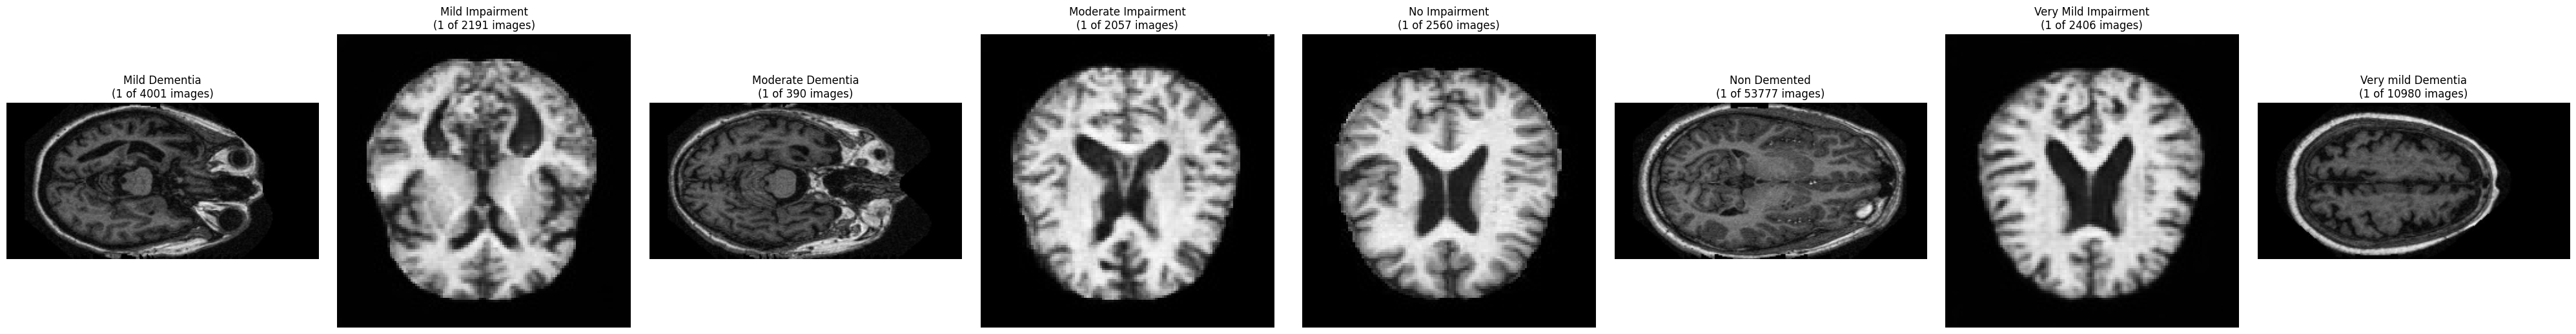

In [7]:
import os
import random
import matplotlib.pyplot as plt
import PIL

# 🔹 Apna dataset ka training folder path yahan likho:
train_dir = "alzheimer_split/train"  # <-- Change karo agar path alag ho

print(f"🎨 Showing one random image from each class in: {train_dir}\n")

try:
    # Sab class folders nikal lo (sirf directories)
    class_names = sorted([d for d in os.listdir(train_dir) if os.path.isdir(os.path.join(train_dir, d))])
    num_classes = len(class_names)
    if num_classes == 0:
        raise FileNotFoundError("❌ No class subfolders found in the training directory.")

    # Figure set up
    fig, axes = plt.subplots(1, num_classes, figsize=(5*num_classes, 5))
    if num_classes == 1:
        axes = [axes]

    for i, class_name in enumerate(class_names):
        class_path = os.path.join(train_dir, class_name)
        image_files = [f for f in os.listdir(class_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

        ax = axes[i]

        if image_files:
            random_image = random.choice(image_files)
            image_path = os.path.join(class_path, random_image)

            img = PIL.Image.open(image_path).convert("RGB")
            ax.imshow(img)
            ax.set_title(f"{class_name}\n(1 of {len(image_files)} images)")
        else:
            ax.set_title(f"{class_name}\n(Empty Folder)")
            print(f"⚠️ Warning: No images found in '{class_name}' folder.")

        ax.axis('off')

    plt.tight_layout()
    plt.show()

except FileNotFoundError as e:
    print(f"🚫 ERROR: {e}")
    print("Please check your dataset path and ensure it contains subfolders with images.")


--- 📊 Training Data Distribution ---


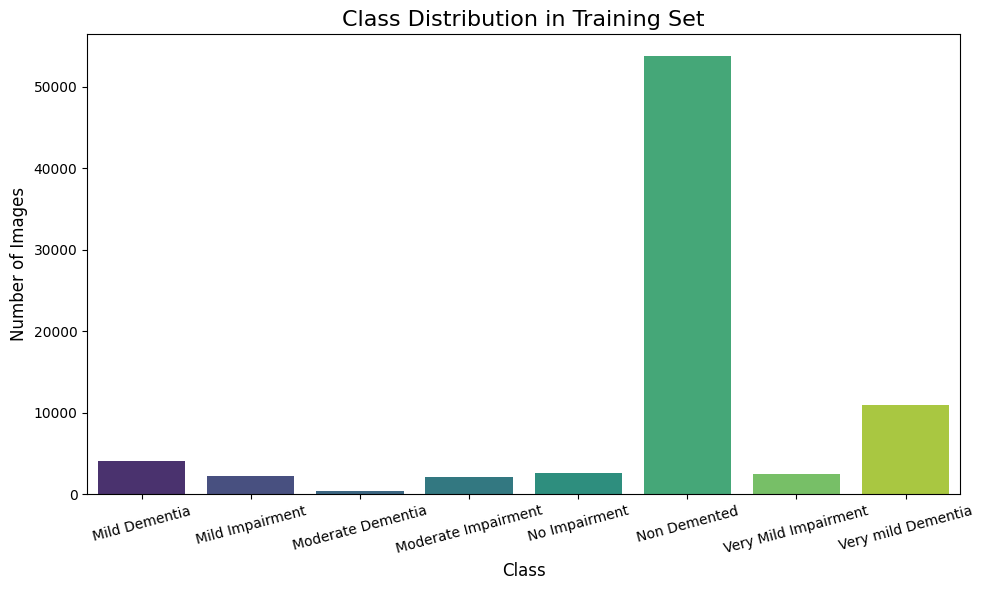

                      Count
Mild Dementia          4001
Mild Impairment        2191
Moderate Dementia       390
Moderate Impairment    2057
No Impairment          2560
Non Demented          53777
Very Mild Impairment   2406
Very mild Dementia    10980

--- 📊 Testing Data Distribution ---


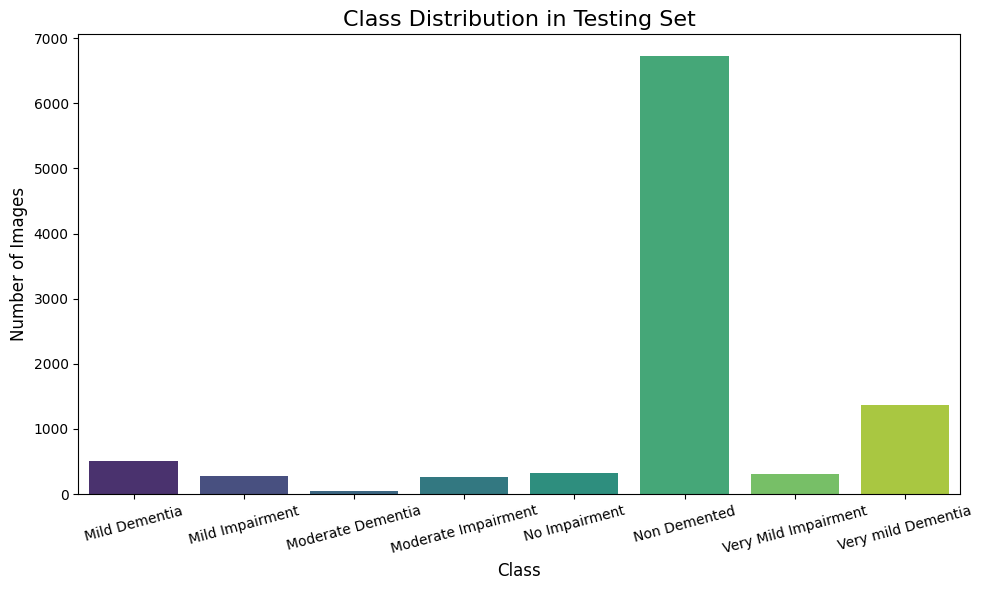

                      Count
Mild Dementia           501
Mild Impairment         275
Moderate Dementia        50
Moderate Impairment     258
No Impairment           320
Non Demented           6723
Very Mild Impairment    302
Very mild Dementia     1373


In [9]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def analyze_class_distribution(data_dir, title):
    """
    Yeh function har class folder ke andar images ki ginti karta hai
    aur ek bar chart plot karta hai.
    """
    if not os.path.exists(data_dir):
        print(f"🚫 ERROR: Path '{data_dir}' not found.")
        return None

    class_counts = {}
    for class_name in sorted(os.listdir(data_dir)):
        class_path = os.path.join(data_dir, class_name)
        if os.path.isdir(class_path):
            # Sirf image files count karte hain
            image_files = [f for f in os.listdir(class_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
            class_counts[class_name] = len(image_files)

    if not class_counts:
        print(f"⚠️ Warning: No class folders or images found in {data_dir}")
        return None

    df = pd.DataFrame.from_dict(class_counts, orient='index', columns=['Count'])

    # 🎨 Plot the bar chart
    plt.figure(figsize=(10, 6))
    sns.barplot(x=df.index, y=df['Count'], palette='viridis')
    plt.title(f'Class Distribution in {title} Set', fontsize=16)
    plt.xlabel('Class', fontsize=12)
    plt.ylabel('Number of Images', fontsize=12)
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

    return df


# 🔹 Apne dataset ke paths yahan likho
train_dir = "alzheimer_split/train"
test_dir = "alzheimer_split/test"

print("--- 📊 Training Data Distribution ---")
train_dist = analyze_class_distribution(train_dir, "Training")
if train_dist is not None:
    print(train_dist)

print("\n--- 📊 Testing Data Distribution ---")
test_dist = analyze_class_distribution(test_dir, "Testing")
if test_dist is not None:
    print(test_dist)


📷 Analyzing image dimensions in: alzheimer_split/train


Analyzing train: 100%|██████████| 8/8 [00:04<00:00,  1.72it/s]


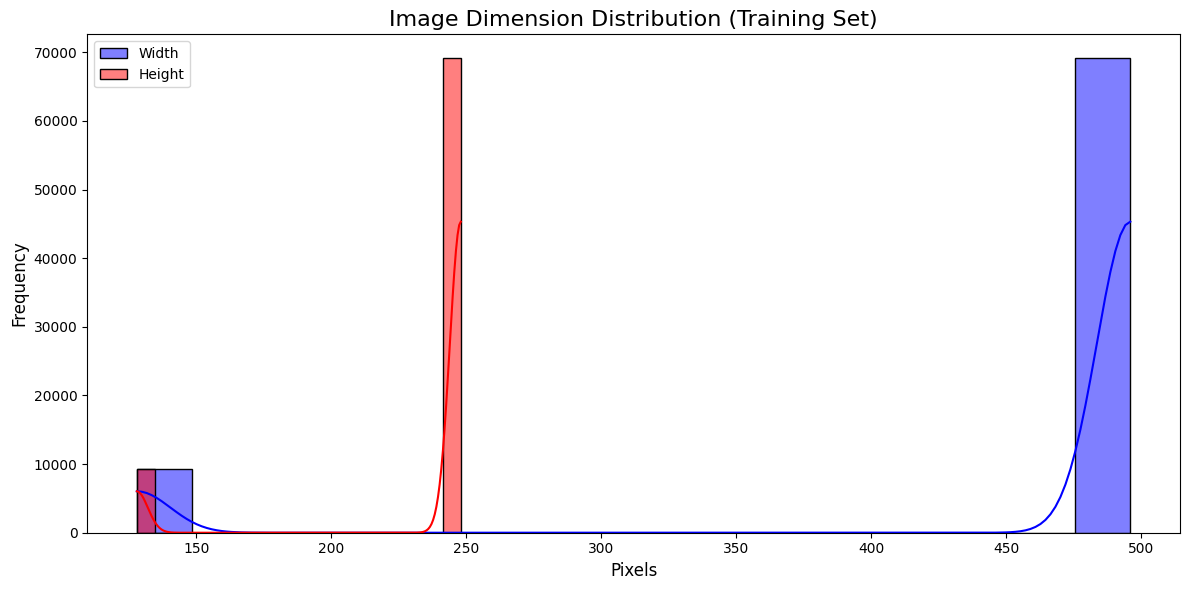


📊 Dimension Summary:
              Width       Height
count  78362.000000  78362.00000
mean     452.729639    233.89010
std      118.538382     38.65382
min      128.000000    128.00000
25%      496.000000    248.00000
50%      496.000000    248.00000
75%      496.000000    248.00000
max      496.000000    248.00000


In [10]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import PIL
from tqdm import tqdm

def analyze_image_dimensions(data_dir):
    """
    Har class folder ke andar images ke dimensions (width, height)
    analyze karta hai aur unka distribution return karta hai.
    """
    if not os.path.exists(data_dir):
        print(f"🚫 ERROR: Path '{data_dir}' not found.")
        return []

    dimensions = []
    for class_name in tqdm(os.listdir(data_dir), desc=f"Analyzing {os.path.basename(data_dir)}"):
        class_path = os.path.join(data_dir, class_name)
        if os.path.isdir(class_path):
            for img_name in os.listdir(class_path):
                if img_name.lower().endswith(('.jpg', '.jpeg', '.png')):
                    try:
                        with PIL.Image.open(os.path.join(class_path, img_name)) as img:
                            dimensions.append(img.size)
                    except Exception as e:
                        print(f"⚠️ Could not open image: {img_name} ({e})")
                        continue

    if not dimensions:
        print("⚠️ No valid images found.")
    return dimensions


# 🔹 Apna dataset path yahaan set karo
train_dir = "alzheimer_split/train"

print(f"📷 Analyzing image dimensions in: {train_dir}")
train_dims = analyze_image_dimensions(train_dir)

if train_dims:
    dims_df = pd.DataFrame(train_dims, columns=['Width', 'Height'])

    # 🎨 Plot histograms
    plt.figure(figsize=(12, 6))
    sns.histplot(dims_df['Width'], color='blue', label='Width', kde=True)
    sns.histplot(dims_df['Height'], color='red', label='Height', kde=True)
    plt.title('Image Dimension Distribution (Training Set)', fontsize=16)
    plt.xlabel('Pixels', fontsize=12)
    plt.ylabel('Frequency', fontsize=12)
    plt.legend()
    plt.tight_layout()
    plt.show()

    print("\n📊 Dimension Summary:")
    print(dims_df.describe())
else:
    print("No dimensions to display — check your training directory path or images.")
